In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('/content/Data_Ready_To_preprocess.csv')

In [3]:
data.head()

,Phone_Name,Brand,RAM,ROM,Network,Accessories_Included,Warranty,Price
0,Samsung Galaxy Z Flip 4,Samsung,8.0,256.0,5G,0,No,"₹ 30,000"
1,Samsung Galaxy Z Flip 7,Samsung,12.0,256.0,5G,Cable,Under warranty (6 month),"₹ 86,999"
2,iPhone 12,iPhone,12.0,64.0,5G,0,Warranty mentioned,"₹ 22,666"
3,Poco C51,poco,6,128,4G,0,0,7890
4,OnePlus Nord,One Plus,8.0,128.0,5G,0,No,"₹ 5,500"


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2362 entries, 0 to 2361
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Phone_Name            2362 non-null   object
 1   Brand                 2362 non-null   object
 2   RAM                   2362 non-null   object
 3   ROM                   2362 non-null   object
 4   Network               2361 non-null   object
 5   Accessories_Included  2362 non-null   object
 6   Warranty              2362 non-null   object
 7   Price                 2362 non-null   object
dtypes: object(8)
memory usage: 147.8+ KB


In [5]:
data.isna().sum()

,0
Phone_Name,0
Brand,0
RAM,0
ROM,0
Network,1
Accessories_Included,0
Warranty,0
Price,0


In [6]:
data.shape

(2362, 8)

In [7]:
data.duplicated().sum()

np.int64(34)

In [8]:
data[data.duplicated()]

,Phone_Name,Brand,RAM,ROM,Network,Accessories_Included,Warranty,Price
121,iPhone 11,iPhone,4,64,5G,0,No,"₹ 15,000"
408,Vivo V70,Vivo,8.0,256.0,5G,0,No,"₹ 45,000"
419,iPhone 15,iPhone,6,128.0,5G,0,No,"₹ 40,000"
520,iPhone 17 Pro Max,iPhone,12,256.0,5G,0,No,"₹ 1,35,000"
531,iPhone 12,iPhone,4,64,5G,Box,No,"₹ 9,000"
670,iPhone 16,iPhone,16.0,128.0,5G,0,No,"₹ 55,000"
725,iPhone 12,iPhone,4,64,5G,0,No,"₹ 15,000"
763,iPhone 13,iPhone,4,128,5G,0,No,"₹ 30,000"
1036,iPhone 15,iPhone,6,128.0,5G,"Box, Cable",No,"₹ 42,000"
1251,Oppo A17,Oppo,4.0,64.0,5G,0,No,"₹ 3,300"


In [9]:
data.drop_duplicates(inplace=True)

In [10]:
data.duplicated().sum()

np.int64(0)

# EDA Summary: `Phone_Name` Column

## 1. Data Quality and Cardinality

- The `Phone_Name` column has **0 missing values**.
- There are **844 unique phone models** in the dataset.
- This means the column has **high cardinality**, because there are many different phone models.

## 2. Most Common Phone Models

- The data is mainly dominated by **Apple iPhones**.
- The **top 10 most frequent phone models are all iPhones**.
- The most common phone is **iPhone 15**, followed by **iPhone 13**.

### Top 5 Most Common Phones

| Rank | Phone Name | Count | Percentage |
|------|------------|-------|------------|
| 1 | **iPhone 15** | 53 | ~2.28% |
| 2 | **iPhone 13** | 51 | ~2.19% |
| 3 | **iPhone 11** | 31 | ~1.33% |
| 4 | **iPhone 14** | 29 | ~1.25% |
| 5 | **iPhone 16** | 28 | ~1.20% |

- **iPhone 15 and iPhone 13 together** make up around **4.5%** of the dataset.
- This shows that these two models are more common than other phone models in the dataset.

## 3. Long Tail of Phone Models

- The dataset contains **844 different phone models**, but most models appear only a few times.
- Many Android phones appear only **once** in the dataset.
- A phone that appears only once represents approximately **0.043%** of the data.
- Some examples are:
  - Motorola Moto G34
  - Vivo Y11 S
  - OnePlus 8T
  - Realme C3
  - OnePlus Nord 6

## 4. Conclusion

- The `Phone_Name` column has **no missing values**.
- It contains **844 unique phone models**.
- **iPhones are the most common phones** in the dataset.
- Most other phone models have very low frequencies.
- Therefore, the `Phone_Name` column is a **high-cardinality categorical feature with a long-tail distribution**.

**Solution**

Convert some lower in a new category Other

In [11]:
data['Phone_Name'] = data['Phone_Name'].str.lower()

In [12]:
data['Phone_Name'].isna().sum()

np.int64(0)

In [13]:
data['Phone_Name'].value_counts()

,count
Phone_Name,
iphone 15,53
iphone 13,51
iphone 11,31
iphone 14,29
iphone 17 pro max,28
...,...
tecno camon pro plus,1
infinix note 40 pro racing edition,1
infinix zero 40,1


In [14]:
data['Phone_Name'].value_counts(normalize=True)*100

,proportion
Phone_Name,
iphone 15,2.276632
iphone 13,2.190722
iphone 11,1.331615
iphone 14,1.245704
iphone 17 pro max,1.202749
...,...
tecno camon pro plus,0.042955
infinix note 40 pro racing edition,0.042955
infinix zero 40,0.042955


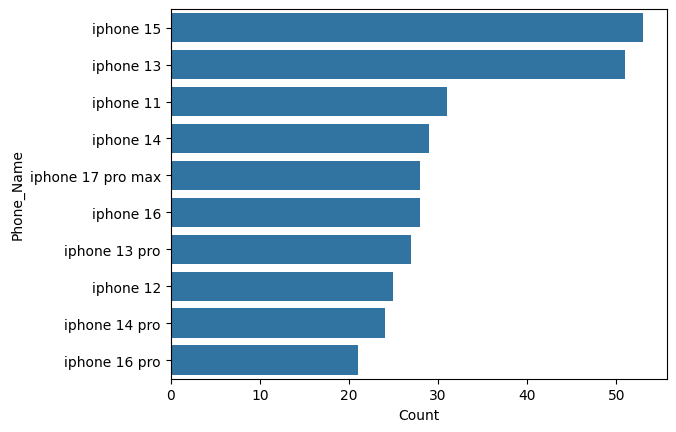

In [15]:
top_10 = data['Phone_Name'].value_counts().head(10)

sns.barplot(x=top_10.values, y=top_10.index)

plt.xlabel('Count')
plt.ylabel('Phone_Name')
plt.show()

# EDA Summary: `Brand` Column

## 1. Data Quality and Missing Values

- The `Brand` column has **0 missing values**.
- This means every row has a brand name.

## 2. Most Common Brands

- **Apple** is the most common brand in the dataset, with around **24.23%** of all entries.
- **Samsung** is the second most common brand, with around **16.58%**.
- **Vivo** is the third most common brand, with around **12.11%**.
- **Realme** is also a major brand, with around **10.18%**.

### Top Brands

| Rank | Brand | Percentage |
|------|-------|------------|
| 1 | **Apple** | ~24.23% |
| 2 | **Samsung** | ~16.58% |
| 3 | **Vivo** | ~12.11% |
| 4 | **Realme** | ~10.18% |

## 3. Visualization Insights

- The distribution of brands is **not equal**.
- A few brands such as **Apple, Samsung, Vivo, and Realme** have a large number of entries.
- Many other brands appear only a few times.
- Some low-frequency brands include:
  - Acer
  - Blackberry
  - Nokia
  - Ulefone
- These brands represent a very small percentage of the dataset.

## 4. Conclusion

- The `Brand` column has **no missing values**.
- **Apple is the most common brand**, followed by Samsung, Vivo, and Realme.
- The distribution has a **long tail**, where a few brands are very common and many brands have very few entries.

In [16]:
data['Brand'] = data['Brand'].str.replace('iPhone', 'apple')

In [17]:
data['Brand'] = data['Brand'].str.lower()

In [18]:
data['Brand'] = data['Brand'].str.replace('mi', 'xiaomi')

In [19]:
data['Brand'] = data['Brand'].str.replace('xiaoxiaomi', 'xiaomi')

In [20]:
data['Brand'] = data['Brand'].str.replace('xiaomicromax', 'micromax')

In [21]:
data['Brand'] = data['Brand'].str.replace('google pixel', 'google')

In [22]:
data['Brand'] = data['Brand'].str.replace('one plus', 'oneplus')

In [23]:
data['Brand'] = data['Brand'].str.strip()

In [24]:
data['Brand'].isna().sum()

np.int64(0)

In [25]:
data['Brand'].value_counts()

,count
Brand,
apple,564
samsung,386
vivo,282
realme,237
oppo,178
xiaomi,138
motorola,104
oneplus,92
lava,46


In [26]:
data['Brand'].nunique()

32

In [27]:
data['Brand'].value_counts(normalize=True)*100

,proportion
Brand,
apple,24.226804
samsung,16.580756
vivo,12.113402
realme,10.180412
oppo,7.646048
xiaomi,5.927835
motorola,4.467354
oneplus,3.951890
lava,1.975945


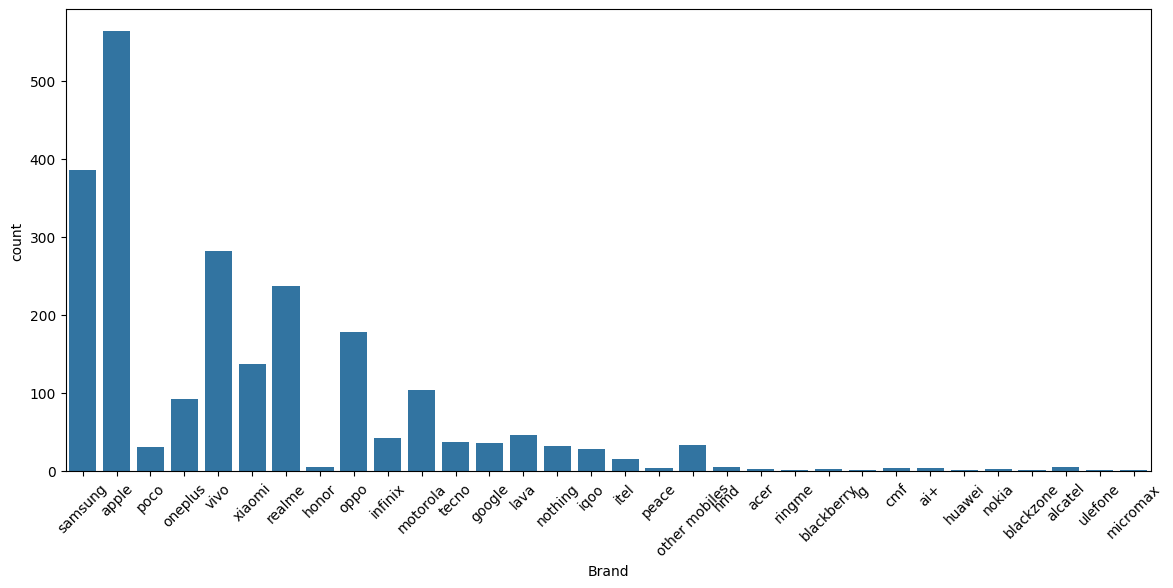

In [28]:
plt.figure(figsize=(14, 6))
sns.countplot(data=data, x='Brand')

plt.xticks(rotation=45)
plt.show()

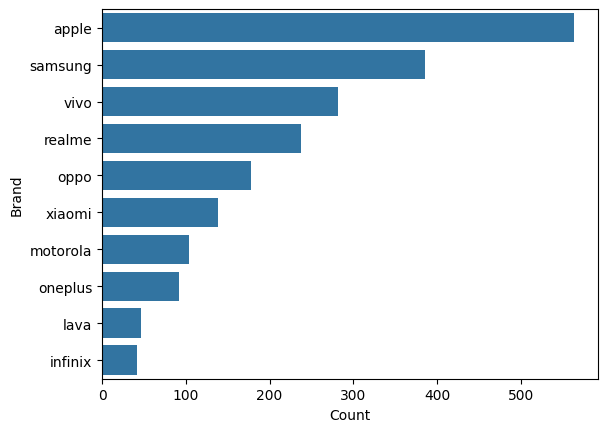

In [29]:
top_10 = data['Brand'].value_counts().head(10)

sns.barplot(x=top_10.values, y=top_10.index)

plt.xlabel('Count')
plt.ylabel('Brand')
plt.show()

# EDA Summary: `RAM` Column

## 1. Data Quality and Missing Values

- The `RAM` column has **0 missing values**.
- There are **11 unique RAM values** in the dataset.
- There are some **data cleaning issues** in this column.
- For example, `"4MB"` is present along with values that represent RAM in **GB**.
- There are also **5 entries with RAM = 0**.
- A phone cannot normally have 0 GB RAM, so these values may represent **missing or incorrect data**.
- The RAM values should be cleaned and converted into a consistent format before further analysis.

## 2. Distribution of RAM

- Most phones in the dataset have **4 GB, 6 GB, 8 GB, or 12 GB RAM**.
- These four RAM sizes together represent **more than 90%** of the dataset.

### Most Common RAM Sizes

| Rank | RAM | Count | Percentage |
|------|-----|-------|------------|
| 1 | **8 GB** | 894 | 38.40% |
| 2 | **6 GB** | 430 | 18.47% |
| 3 | **12 GB** | 415 | 17.82% |
| 4 | **4 GB** | 400 | 17.18% |

- **8 GB RAM** is the most common configuration, with **38.4%** of the phones.
- **6 GB and 12 GB** RAM are the next most common.
- **4 GB RAM** is also very common.

## 3. Visualization Insights

- The countplot clearly shows that **8 GB RAM is the most common**.
- The **4 GB, 6 GB, 8 GB, and 12 GB** categories have much higher frequencies than the other RAM sizes.
- Higher RAM configurations such as **16 GB and 24 GB** appear less frequently.
- Lower configurations such as **1 GB, 2 GB, and 3 GB** are also uncommon.

## 4. Conclusion

- The `RAM` column has **no missing values**, but it contains some **incorrect or inconsistent values**.
- The most common RAM size is **8 GB**.
- Most phones in the dataset have **4 GB to 12 GB RAM**.
- Values such as **`4MB` and `0` should be cleaned** before using this column for further analysis or machine learning.

In [30]:
data['RAM'] = data['RAM'].str.replace('4GB/8', '8')

In [31]:
data['RAM'] = data['RAM'].str.replace('3.0', '3')

In [32]:
data['RAM'] = data['RAM'].str.replace('2.0', '2')

In [33]:
data['RAM'] = data['RAM'].str.replace('24.0', '24')

In [34]:
data['RAM'] = data['RAM'].str.replace('8.0', '8').str.replace('6GB/8GB', '8').str.replace('8GB', '8').str.replace('4GB/8GB', '8')

In [35]:
data['RAM'] = data['RAM'].str.replace('8/12GB', '12').str.replace('12GB/16GB', '16').str.replace('8/12GB/16GB', '16').str.replace('4GB/6GB', '6').str.replace('2GB', '2').str.replace('3GB/4GB', '3')

In [36]:
data['RAM'] = data['RAM'].str.replace('12/16GB', '16').str.replace('3GB', '3').str.replace('16.0', '16').str.replace('6GB', '6').str.replace('4.0', '4').str.replace('6.0', '6')

In [37]:
data['RAM'] = data['RAM'].str.replace('64', '4').str.replace('65', '4').str.replace('28', '8')

In [38]:
data['RAM'] = data['RAM'].str.replace('0.032', '4MB')

In [39]:
data['RAM'].value_counts()

,count
RAM,
8,894
6,430
12,415
4,400
3,78
16,61
2,35
1,6
0,5


In [40]:
data['RAM'].value_counts(normalize=True)*100

,proportion
RAM,
8,38.402062
6,18.470790
12,17.826460
4,17.182131
3,3.350515
16,2.620275
2,1.503436
1,0.257732
0,0.214777


In [41]:
data['RAM'].isna().sum()

np.int64(0)

In [42]:
data['RAM'].nunique()

11

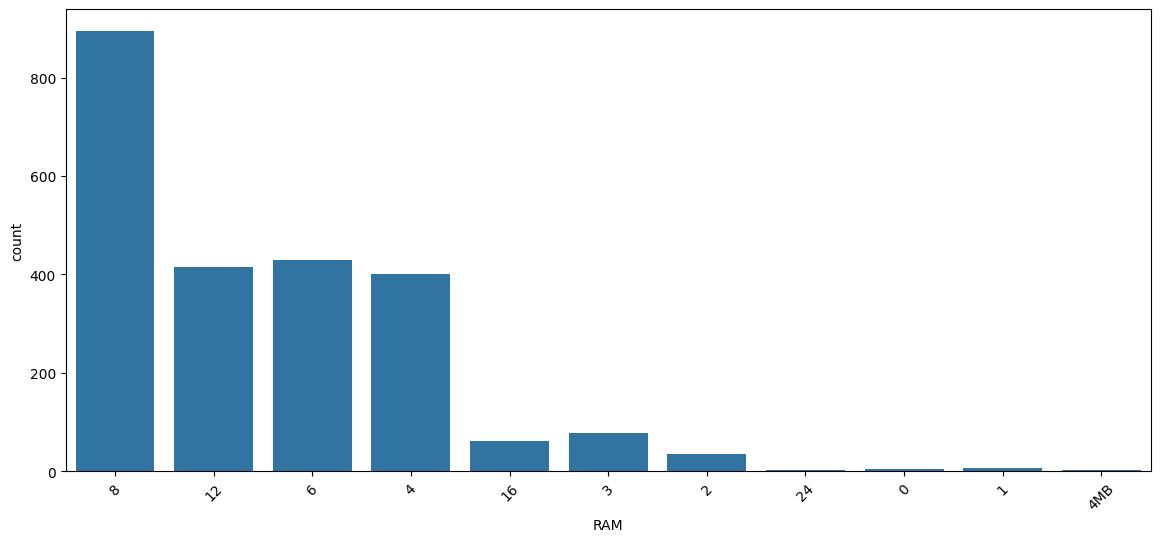

In [43]:
plt.figure(figsize=(14, 6))
sns.countplot(data=data, x='RAM')

plt.xticks(rotation=45)
plt.show()

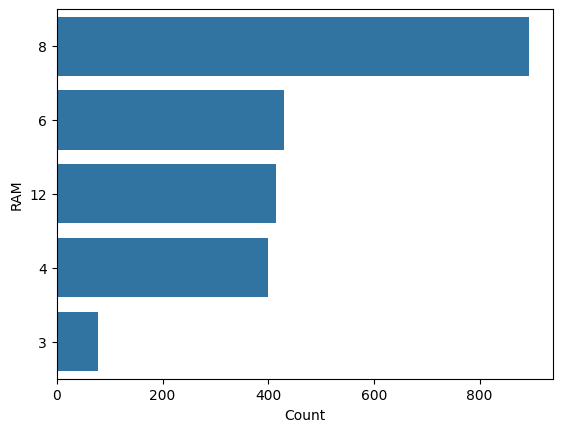

In [44]:
top_10 = data['RAM'].value_counts().head(5)

sns.barplot(x=top_10.values, y=top_10.index)

plt.xlabel('Count')
plt.ylabel('RAM')
plt.show()

# EDA Summary: `ROM` Column

## 1. Data Quality and Missing Values

- The `ROM` column has **0 missing values**.
- There are **12 unique ROM values** in the dataset.
- There are some **data cleaning issues** in this column.
- Most values represent storage in **GB**, but some values are written in **MB**.
- For example:
  - `250MB`
  - `32MB`
  - `4MB`
- There are also **3 entries with ROM = 0**.
- A phone normally does not have 0 GB storage, so these values may represent **missing or incorrect data**.
- The ROM values should be converted into a **consistent format** before further analysis or machine learning.

## 2. Distribution of ROM

- Most phones in the dataset have **128 GB or 256 GB** storage.
- **128 GB** is the most common ROM size, with **45.79%** of the phones.
- **256 GB** is the second most common, with **32.43%**.
- **64 GB** and **512 GB** are the next most common storage sizes.

### Most Common ROM Sizes

| Rank | ROM | Count | Percentage |
|------|-----|-------|------------|
| 1 | **128 GB** | 1066 | 45.79% |
| 2 | **256 GB** | 755 | 32.43% |
| 3 | **64 GB** | 263 | 11.30% |
| 4 | **512 GB** | 162 | 6.96% |

- **128 GB and 256 GB together account for more than 78%** of the dataset.

## 3. Visualization Insights

- The countplot clearly shows that **128 GB and 256 GB are the most common storage sizes**.
- Other storage sizes such as **64 GB and 512 GB** appear less frequently.
- Very small or unusual values such as **16 GB, 1024 GB, and MB values** occur very rarely.
- This creates a **long-tail distribution**, where a few ROM sizes are very common and many others appear only a few times.

In [45]:
data['ROM'] = data['ROM'].str.replace('128.0', '128').str.replace('256.0', '256').str.replace('512.0', '512').str.replace('64.0', '64').str.replace('128GB', '128').str.replace('256GB', '256').str.replace('32.0', '32').str.replace('16GB', '16')

In [46]:
data['ROM'] = data['ROM'].str.replace('64GB', '64').str.replace('16.0', '16').str.replace('32GB', '32')

In [47]:
rom_updates = {
    156: "128 GB",
    199: "64 GB",
    333: "128 GB",
    397: "32 GB",
    608: "64 GB",
    640: "64 GB",
    922: "64 GB",
    1065: "128 GB",
    1347: "64 GB",
    1434: "128 GB",
    1693: "128 GB",
    1784: "32 GB",
    1903: "64 GB",
    2320: "64 GB",
}

for idx, val in rom_updates.items():
    if idx in data.index:
        data.loc[idx, "ROM"] = val

In [48]:
rom_updates = {
    56: "128 GB",
    100: "128 GB",
    348: "128 GB",
    414: "256 GB",
    512: "128 GB",
    522: "128 GB",
    537: "128 GB",
    561: "128 GB",
    586: "128 GB",
    686: "128 GB",
    691: "128 GB",
    696: "128 GB",
    707: "128 GB",
    722: "128 GB",
    732: "128 GB",
    736: "128 GB",
    891: "256 GB",
    903: "128 GB",
    913: "128 GB",
    934: "128 GB",
    1130: "128 GB",
}

# Mapping of Index -> Correct Brand value (based on your notes)
brand_updates = {
    691: "iQOO",
    707: "iQOO",
    903: "Xiaomi"
}

# Update the 'ROM' column for the specified indices
for idx, val in rom_updates.items():
    if idx in data.index:
        data.loc[idx, "ROM"] = val

# Update the 'Brand' column for the specified indices
for idx, val in brand_updates.items():
    if idx in data.index:
        data.loc[idx, "Brand"] = val

In [49]:
rom_updates = {
    1141: "128 GB",
    1172: "256 GB",
    1226: "128 GB",
    1235: "128 GB",
    1349: "128 GB",
    1403: "128 GB",
    1405: "256 GB",
    1445: "128 GB",
    1465: "128 GB",
    1499: "128 GB",
    1570: "128 GB",
    1659: "128 GB",
    1727: "128 GB",
    1776: "128 GB",
    1780: "128 GB",
    1788: "128 GB",
    1809: "128 GB",
    1838: "128 GB",
    1889: "128 GB",
    2081: "128 GB",
    2188: "128 GB",
    2297: "128 GB",
    2313: "128 GB",
    2331: "128 GB",
}

# Mapping of Index -> Correct Brand value (based on your notes)
brand_updates = {
    1172: "iQOO",
    1403: "POCO",
    1776: "iQOO"
}

# Update the 'ROM' column for the specified indices
for idx, val in rom_updates.items():
    if idx in data.index:
        data.loc[idx, "ROM"] = val

# Update the 'Brand' column for the specified indices
for idx, val in brand_updates.items():
    if idx in data.index:
        data.loc[idx, "Brand"] = val

In [50]:
import pandas as pd

# Mapping of Index -> Correct ROM value
rom_updates = {
    352: "32 GB",
    848: "128 GB",
    1470: "64 GB",
}

# Update the 'ROM' column for the specified indices
for idx, val in rom_updates.items():
    if idx in data.index:
        data.loc[idx, "ROM"] = val

In [51]:
data['ROM'] = data['ROM'].str.replace('128/256/512GB', '512').str.replace('256/512GB', '512')

In [52]:
data['ROM'] = data['ROM'].str.replace('64/128/256', '64')

In [53]:
data['ROM'] = data['ROM'].str.replace('512/1TB', '1024').str.replace('16/32', '16').str.replace('32/128', '128').str.replace('68.0', '64').str.replace('34.0', '32')

In [54]:
data['ROM'] = data['ROM'].str.replace('0.024', '32MB')

In [55]:
data['ROM'] = data['ROM'].str.replace('GB', '').str.strip()

In [56]:
data['ROM'] = data['ROM'].str.replace('32/64', '32')

In [57]:
data['ROM'].isna().sum()

np.int64(0)

In [58]:
data['ROM'].nunique()

12

In [59]:
data['ROM'].value_counts()

,count
ROM,
128,1066
256,755
64,263
512,162
32,43
16,19
1024,13
0,3
250MB,1


In [60]:
data['ROM'].value_counts(normalize=True)*100

,proportion
ROM,
128,45.790378
256,32.431271
64,11.297251
512,6.958763
32,1.847079
16,0.816151
1024,0.558419
0,0.128866
250MB,0.042955


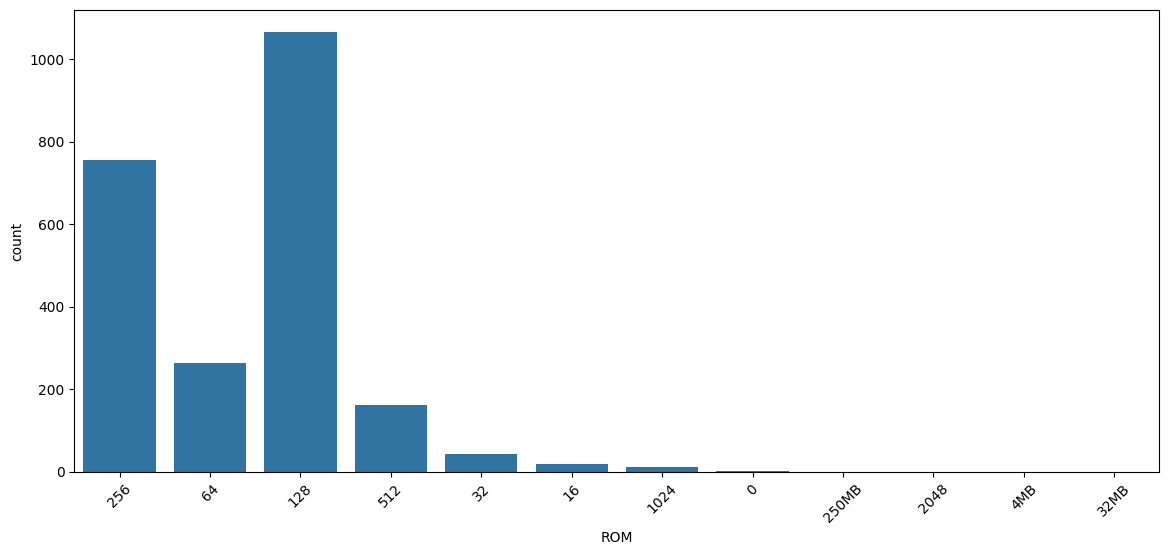

In [61]:
plt.figure(figsize=(14, 6))
sns.countplot(data=data, x='ROM')

plt.xticks(rotation=45)
plt.show()

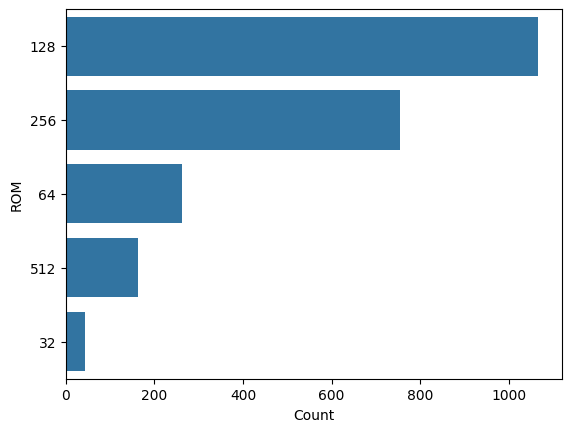

In [62]:
top_10 = data['ROM'].value_counts().head(5)

sns.barplot(x=top_10.values, y=top_10.index)

plt.xlabel('Count')
plt.ylabel('ROM')
plt.show()

# EDA Summary: `Network` Column

## 1. Data Quality and Missing Values

- The `Network` column has **1 missing value**.
- There are **3 different network types** in the dataset:
  - 5G
  - 4G
  - 2G

## 2. Network Distribution

- **5G** is the most common network type, with **1,878 devices**.
- 5G represents approximately **80.7%** of the dataset.
- **4G** is the second most common network, with **448 devices**.
- 4G represents approximately **19.3%** of the dataset.
- **2G** appears only **1 time** in the dataset.
- 2G represents approximately **0.04%** of the data, so it is almost invisible in the pie chart.

### Network Distribution

| Network | Count | Percentage |
|---------|-------|------------|
| **5G** | 1,878 | ~80.7% |
| **4G** | 448 | ~19.3% |
| **2G** | 1 | ~0.04% |
| **Missing** | 1 | - |

## 3. Visualization Insights

- The countplot clearly shows that **5G devices are much more common than 4G devices**.
- The number of **2G devices is extremely small**, so it is difficult to see in the countplot.
- The pie chart shows that the network distribution is approximately an **80/20 split between 5G and 4G**.

## 4. Conclusion

- **5G dominates the dataset**, accounting for around 80.7% of the devices.
- **4G** accounts for around 19.3%.
- **2G is extremely rare**, with only one device.
- There is **1 missing value** that should be handled before further analysis or machine learning.

In [63]:
data['Network'] = data['Network'].str.replace('3G', '5G')

In [64]:
dist = {
    117: '4G',
    268: '4G',
    486: '4G',
    892: '4G',
    942: '4G',
    1011: '4G',
    1026: '4G',
    1102: '4G',
    1280: '4G',
    1321: '4G',
    1497: '4G',
    1753: '4G'
}

for index, network in dist.items():
    data.loc[index, 'Network'] = network

In [65]:
final_dataset = {
    42: "4G",
    126: "4G",
    260: "4G",
    287: "4G",
    311: "4G",
    381: "4G",
    397: "4G",
    413: "4G",
    480: "4G",
    500: "4G",
    581: "4G",
    652: "4G",
    657: "4G",
    1149: "4G",
    1433: "4G",
    1554: "4G",
    1683: "4G",
    1760: "4G",
    1775: "4G",
    1784: "4G"
}

for index, network in final_dataset.items():
    data.loc[index, 'Network'] = network

In [66]:
final_dataset = {
    1869: "4G",
    1959: "4G",
    1983: "4G",
    1989: "4G",
    2073: "4G",
    2162: "5G",
    2194: "4G",
    2213: "4G",
    2237: "4G",
    2327: "4G",
    2351: "4G"
}


for index, network in final_dataset.items():
    data.loc[index, 'Network'] = network

In [67]:
data['Network'].value_counts()

,count
Network,
5G,1878
4G,448
2G,1


In [68]:
data['Network'].value_counts(normalize=True)*100

,proportion
Network,
5G,80.704770
4G,19.252256
2G,0.042974


In [69]:
data['Network'].isna().sum()

np.int64(1)

In [70]:
data['Network'].nunique()

3

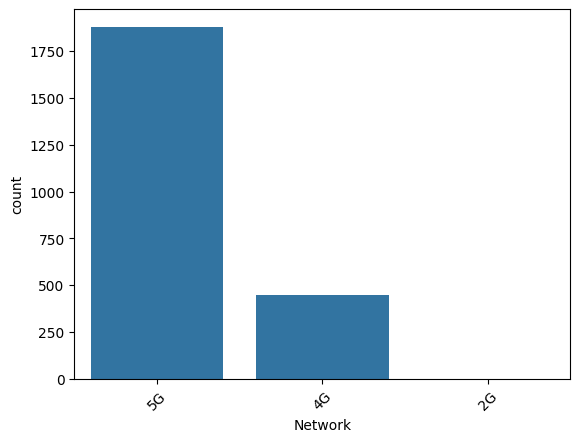

In [71]:
# plt.figure(figsize=(14, 6))
sns.countplot(data=data, x='Network')

plt.xticks(rotation=45)
plt.show()

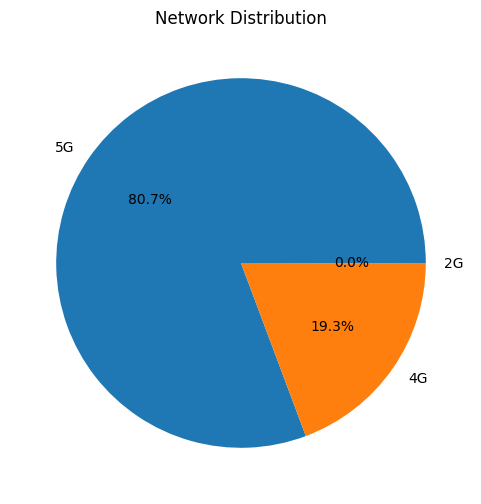

In [72]:
data['Network'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6)
)

plt.ylabel('')
plt.title('Network Distribution')
plt.show()

# EDA Summary: `Warranty` Column

## 1. Data Quality and Missing Values

- The `Warranty` column has **0 missing values**.
- It contains only **two categories**:
  - `Yes`
  - `No`
- Therefore, `Warranty` is a **binary categorical variable**.

## 2. Warranty Distribution

- Most phones in the dataset **do not have a warranty**.
- **No** is the most common category, with **2,183 devices**.
- This represents approximately **93.8%** of the dataset.
- **Yes** appears for only **145 devices**, representing approximately **6.2%** of the dataset.

### Warranty Distribution

| Warranty | Count | Percentage |
|----------|-------|------------|
| **No** | 2,183 | ~93.8% |
| **Yes** | 145 | ~6.2% |

## 3. Visualization Insights

- The countplot clearly shows that **"No" is much more common than "Yes"**.
- The pie chart also shows a large difference between the two categories.
- The distribution is approximately **94% without warranty and 6% with warranty**.

## 4. Conclusion

- The `Warranty` column has **no missing values**.
- It is a **binary categorical column**.
- The data is **highly imbalanced**, because most phones do not have a warranty.
- If this column is used as a target variable in a machine learning model, the class imbalance should be handled carefully.

In [73]:
data['Warranty'] = data['Warranty'].str.replace('0', 'No')

In [74]:
data['Warranty'] = data['Warranty'].str.replace('No warranty', 'No')

In [75]:
data.loc[data[~(data['Warranty'] == 'No')].index, 'Warranty'] = 'Yes'

In [76]:
data['Warranty'].isna().sum()

np.int64(0)

In [77]:
data['Warranty'].value_counts()

,count
Warranty,
No,2183
Yes,145


In [78]:
data['Warranty'].value_counts(normalize=True)*100

,proportion
Warranty,
No,93.771478
Yes,6.228522


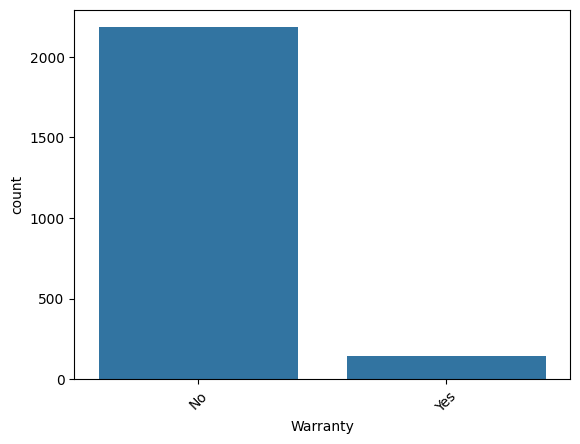

In [79]:
sns.countplot(data=data, x='Warranty')

plt.xticks(rotation=45)
plt.show()

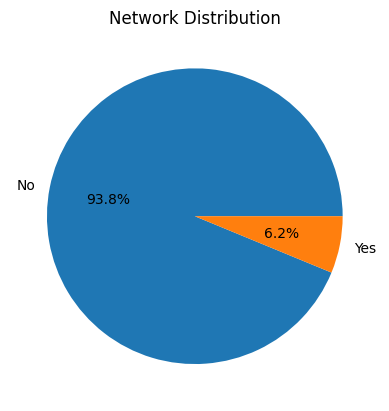

In [80]:
data['Warranty'].value_counts().plot(kind='pie', autopct='%1.1f%%')

plt.ylabel('')
plt.title('Network Distribution')
plt.show()

In [81]:
data.sample(4)

,Phone_Name,Brand,RAM,ROM,Network,Accessories_Included,Warranty,Price
1542,iphone 15,apple,6,128,5G,0,No,"₹ 44,000"
364,realme p1 pro,realme,8,128,5G,0,No,"₹ 9,000"
1358,realme 16 pro,realme,12,16,5G,"Box, Bill",No,"₹ 30,000"
970,lava o3,lava,4,64,4G,0,No,5749


# EDA Summary: `Price` Column

## 1. Descriptive Statistics

- The `Price` column contains **2,328 values**.
- There are **0 missing values**.
- There are **665 unique price values**.
- The **average price** is around **₹29,335.86**.
- The **median price** is **₹20,000**.
- The minimum phone price is **₹500**.
- The maximum phone price is **₹2,29,900**.

## 2. Data Distribution

- The histogram and boxplot show that the `Price` column is **right-skewed**.
- This means most phones have **low or medium prices**, while a small number of phones have very high prices.
- The **skewness is 2.46**, which confirms that the data is strongly right-skewed.
- The **kurtosis is 7.84**, which indicates the presence of heavy tails and extreme values.
- After applying a **log transformation**, the distribution becomes much more balanced.
- The skewness decreases to around **-0.16** and the kurtosis becomes **0.31**.

## 3. Outlier Analysis

- Using the **IQR method**, the upper limit is **₹72,751.5**.
- The lower limit is **-₹25,252.5**, but negative prices are not possible, so the lower bound is not practically useful.
- Any phone with a price **above ₹72,751.5** is considered a statistical outlier.
- These high-price outliers represent approximately **7.47%** of the dataset.

## 4. Conclusion

- The `Price` column has **no missing values**.
- Most phones are in the **low to mid-price range**, while a small number of premium phones have very high prices.
- The data is **strongly right-skewed** because of these expensive phones.
- Around **7.47% of the prices are statistical outliers** according to the IQR method.
- A **log transformation** can be useful if this feature is used in a machine learning model because it reduces the effect of the strong right skew.

In [82]:
data['Price'] = data['Price'].str.replace('₹', '').str.strip()

In [83]:
data['Price'] = data['Price'].str.replace(',', '').str.strip()

In [84]:
data['Price'] = data['Price'].astype(int)

In [85]:
data[data['Price'] == 500]

,Phone_Name,Brand,RAM,ROM,Network,Accessories_Included,Warranty,Price
299,vivo x300,vivo,12,256,5G,0,No,500
430,samsung,samsung,0,0,4G,0,No,500


In [86]:
data.loc[299, 'Price'] = 42000

In [87]:
data['Price'].describe()

,Price
count,2328.000000
mean,29335.865120
std,28758.525152
min,500.000000
25%,11499.000000
50%,20000.000000
75%,36000.000000
max,229900.000000


In [88]:
data['Price'].isna().sum()

np.int64(0)

In [89]:
data['Price'].nunique()

665

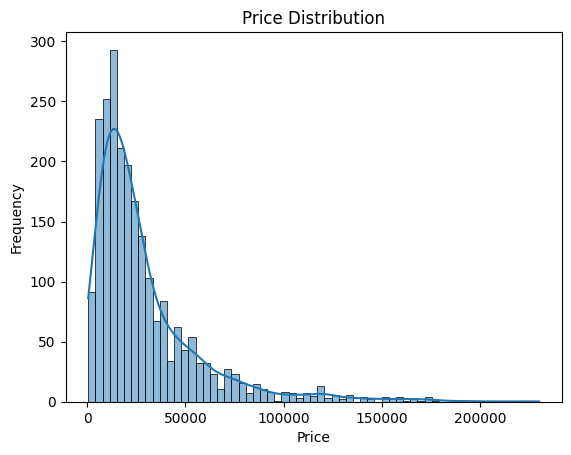

In [90]:
sns.histplot((data['Price']), kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

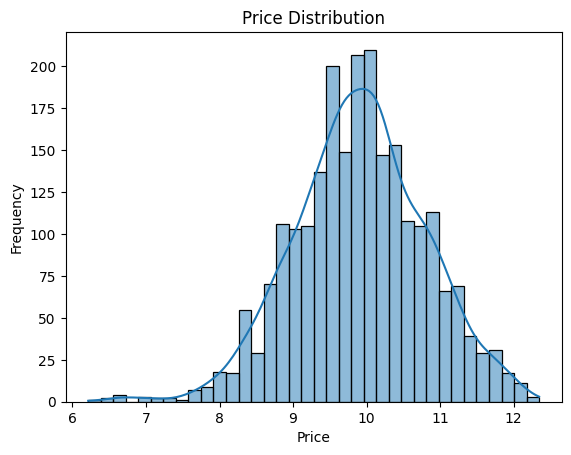

In [91]:
sns.histplot(np.log(data['Price']), kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

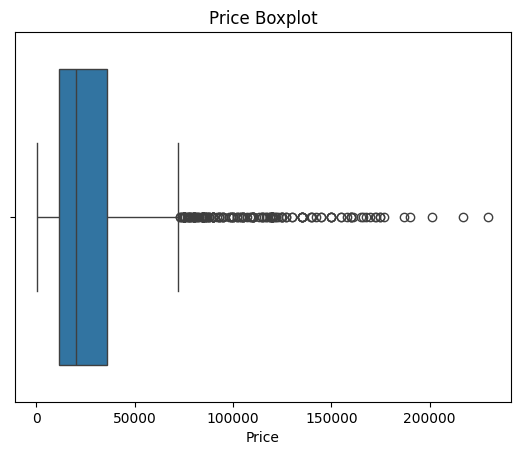

In [92]:
sns.boxplot(x=data['Price'])

plt.title('Price Boxplot')
plt.xlabel('Price')
plt.show()

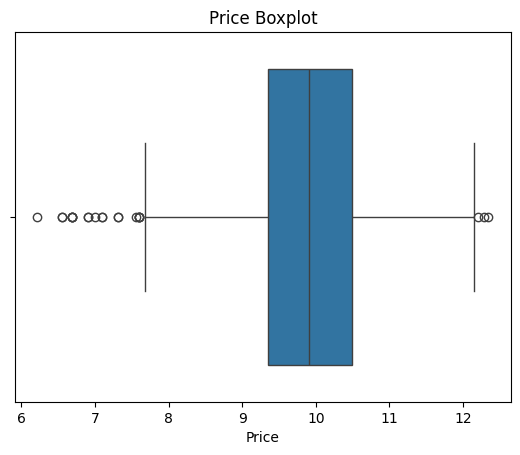

In [93]:
sns.boxplot(x=np.log1p(data['Price']))

plt.title('Price Boxplot')
plt.xlabel('Price')
plt.show()

In [94]:
np.log(data['Price']).describe()

,Price
count,2328.000000
mean,9.907632
std,0.889163
min,6.214608
25%,9.350015
50%,9.903488
75%,10.491274
max,12.345400


In [95]:
data['Price'].skew()

np.float64(2.46118190367505)

In [96]:
np.log(data['Price']).skew()

np.float64(-0.16699108600635368)

In [97]:
data['Price'].kurt()

np.float64(7.84419929986887)

In [98]:
np.log(data['Price']).kurt()

np.float64(0.31451343879747684)

In [99]:
Q1 = data['Price'].quantile(0.25)
Q3 = data['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound: ", lower_bound)
print("Upper bound: ", upper_bound)

Lower bound:  -25252.5
Upper bound:  72751.5


In [100]:
outliers = data[
    (data['Price'] < lower_bound) |
    (data['Price'] > upper_bound)
]

(len(outliers)/len(data))*100

7.474226804123711

# EDA Summary: `Accessories_Included` Column

## 1. Data Quality and Summary Statistics

- The `Accessories_Included` column contains **2,328 entries**.
- There are **0 missing values**.
- Most phones, **1,668 devices**, have **0 accessories** included.
- The next most common values are:
  - **2 accessories** → 235 devices
  - **1 accessory** → 167 devices
- The average number of accessories is approximately **0.67** per phone.

## 2. Distribution and Outliers

- The data is **strongly right-skewed**.
- The **median is 0**, which means at least half of the phones have no accessories included.
- The histogram shows a very large number of phones with **0 accessories**, while higher values occur much less frequently.
- The boxplot shows that values above **2 accessories** are considered statistical outliers.
- The outlier values include **3, 4, 5, 6, and 8 accessories**.
- These values are statistically unusual because only a small number of phones have many accessories.

## 3. Log Transformation

- A `log1p` transformation can be used to reduce the effect of the right-skewed distribution.
- After applying `np.log1p`, the maximum value decreases from **8.0 to approximately 2.20**.
- The mean after transformation becomes approximately **0.33**.
- The 75th percentile becomes approximately **0.69**.
- This transformation makes the data more suitable for some machine learning algorithms.

## 4. Conclusion

- The `Accessories_Included` column has **no missing values**.
- Most phones have **0 accessories** included.
- The column is **strongly right-skewed**.
- Values above **2 accessories** are statistical outliers.
- The `log1p` transformation reduces the effect of extreme values and compresses the distribution.

In [102]:
data.shape

(2328, 8)

In [103]:
data['Accessories_Included'].isna().sum()

np.int64(0)

In [104]:
data['Accessories_Included'].value_counts()

,count
Accessories_Included,
0,1668
"Box, Bill",150
Box,98
"Box, Bill, Charger",87
Charger,57
"Box, Bill, Cable",54
"Box, Charger",53
Bill,52
"Bill, Charger",21


In [105]:
data['Accessories_Included'].value_counts(normalize=True)*100

,proportion
Accessories_Included,
0,71.649485
"Box, Bill",6.443299
Box,4.209622
"Box, Bill, Charger",3.737113
Charger,2.448454
"Box, Bill, Cable",2.319588
"Box, Charger",2.276632
Bill,2.233677
"Bill, Charger",0.902062


In [106]:
score = {
    'Box': 1,
    'Bill': 1,
    'Cable': 1,
    'Charger': 2,
    'Original Kit': 4
}

def calculate_score(value):
    if value == 0 or value == '0':
        return 0

    items = value.split(', ')

    total = 0
    for item in items:
        total += score.get(item, 0)

    return total

data['Accessories_Included'] = data['Accessories_Included'].apply(calculate_score)

In [107]:
data['Accessories_Included'].value_counts()

,count
Accessories_Included,
0,1668
2,235
1,167
3,132
4,105
5,17
8,3
6,1


In [108]:
data['Accessories_Included'].isna().sum()

np.int64(0)

In [109]:
data['Accessories_Included'].describe()

,Accessories_Included
count,2328.000000
mean,0.673540
std,1.238942
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,8.000000


<Axes: >

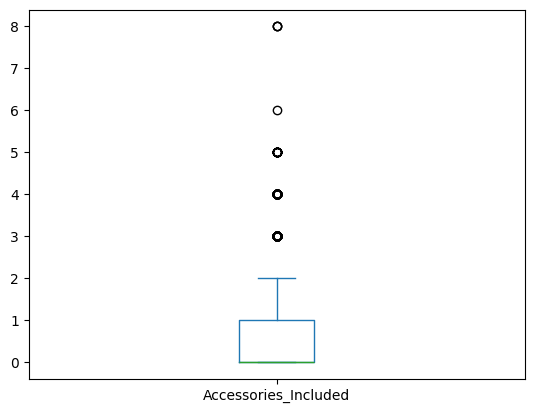

In [110]:
data['Accessories_Included'].plot(kind='box')

<Axes: >

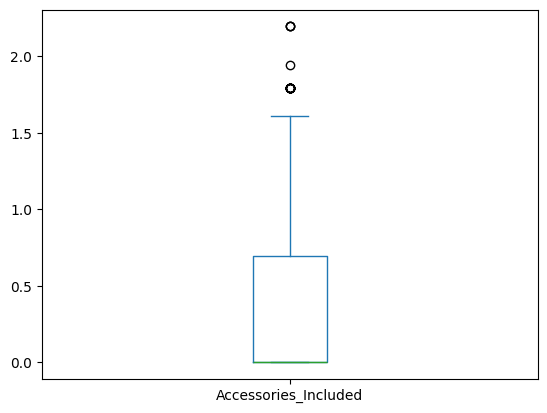

In [111]:
np.log1p(data['Accessories_Included']).plot(kind='box')

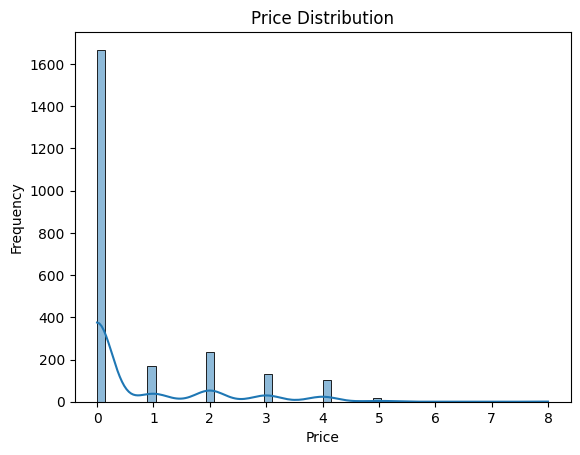

In [112]:
sns.histplot((data['Accessories_Included']), kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

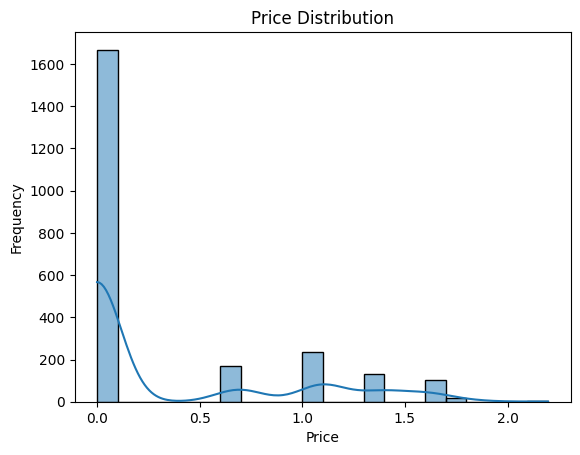

In [113]:
sns.histplot(np.log1p(data['Accessories_Included']), kde=True)

plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [114]:
data['Accessories_Included'].describe()

,Accessories_Included
count,2328.000000
mean,0.673540
std,1.238942
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,8.000000


In [115]:
np.log1p(data['Accessories_Included']).describe()

,Accessories_Included
count,2328.000000
mean,0.328569
std,0.552779
min,0.000000
25%,0.000000
50%,0.000000
75%,0.693147
max,2.197225


In [116]:
data['Accessories_Included'].value_counts()

,count
Accessories_Included,
0,1668
2,235
1,167
3,132
4,105
5,17
8,3
6,1


In [117]:
np.log1p(data['Accessories_Included']).value_counts()

,count
Accessories_Included,
0.000000,1668
1.098612,235
0.693147,167
1.386294,132
1.609438,105
1.791759,17
2.197225,3
1.945910,1


In [120]:
data.to_csv('univariate_EDA.csv', index=False)